# Практическая работа 5. Алгоритм PageRank в Python

Алгоритм PageRank предложили Ларри Пейдж и Сергей Брин в 1996 году. Страница считается важной,
если на неё ссылаются другие важные страницы.

**Модель случайного блуждания.** Пользователь кликает по случайной исходящей ссылке текущей страницы с вероятностью $\beta$,
а с вероятностью $1-\beta$ телепортируется на случайную страницу из всех $N$:

$$r_j = \sum_{i \to j} \beta \frac{r_i}{d_i} + \frac{1-\beta}{N}$$

В матричной форме $r = \beta M r + \frac{1-\beta}{N}\mathbf{1}$, где $M_{ji} = 1/d_i$, если есть ссылка $i \to j$.
Эквивалентно, $r$ — главный собственный вектор «матрицы Google» $A = \beta M + \frac{1-\beta}{N}\mathbf{1}\mathbf{1}^T$ с собственным числом 1.

Алгоритм (как в задании):
1. **Инициализация:** всем страницам присваивается одинаковый ранг $1/N$.
2. **Обновление рангов:** ранги пересчитываются по формуле выше.
3. **Повторение шага 2**, пока ранги не сойдутся ($\|r^{(t+1)} - r^{(t)}\|_1 < \varepsilon$).

План ноутбука:
1. Пример 1 из задания (`nx.pagerank`).
2. Собственная реализация: итеративная (по формуле), матричная (power iteration) и через собственный вектор, сравнение с NetworkX.
3. Проблемы базового принципа (тупики и паучьи ловушки) и как их снимает телепортация.
4. Влияние коэффициента затухания и персонализированный PageRank.
5. Пример 2 из задания: краулер (requests + BeautifulSoup), граф ссылок реального сайта и его ранжирование.

In [1]:
# !pip install networkx requests beautifulsoup4 matplotlib pandas
import json, os, time
from collections import deque
from urllib.parse import urljoin, urlparse, unquote

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup

## 1. Пример 1 из задания: ранг страниц для заданного набора ссылок

In [2]:
# Создаем граф ссылок
G = nx.DiGraph()
G.add_edges_from([(1, 2), (1, 3), (2, 3), (3, 1)])

# Вычисляем ранг страниц
pagerank = nx.pagerank(G)

# Выводим ранг каждой страницы
for page, rank in pagerank.items():
    print(f"Страница {page}: ранг {rank:.4f}")

Страница 1: ранг 0.3878
Страница 2: ранг 0.2148
Страница 3: ранг 0.3974


Страница 3 получает ссылки от 1 и 2, поэтому её ранг самый высокий. Страница 1 получает единственную ссылку,
но от самой важной страницы 3 (которая отдаёт ей весь свой ранг), поэтому она на втором месте.
Страница 2 получает только половину ранга страницы 1.

## 2. Собственная реализация

### 2.1 Итеративная, по определению (шаги 1–3 из задания)
Отдельно обрабатываем **тупики** (dangling nodes), то есть страницы без исходящих ссылок: их ранг равномерно раздаём всем страницам
(так делает и NetworkX).

In [3]:
def pagerank_iterative(G, beta=0.85, eps=1e-10, max_iter=100, verbose=False):
    nodes = list(G.nodes())
    N = len(nodes)
    r = {v: 1 / N for v in nodes}                       # шаг 1: инициализация
    out_deg = dict(G.out_degree())
    for it in range(max_iter):
        dangling = sum(r[v] for v in nodes if out_deg[v] == 0)
        r_new = {}
        for j in nodes:                                 # шаг 2: обновление
            s = sum(r[i] / out_deg[i] for i in G.predecessors(j))
            r_new[j] = beta * (s + dangling / N) + (1 - beta) / N
        diff = sum(abs(r_new[v] - r[v]) for v in nodes)
        r = r_new
        if verbose:
            print(f"итерация {it + 1:2d}: " + "  ".join(f"{v}:{r[v]:.4f}" for v in nodes) + f"   |Δ|={diff:.2e}")
        if diff < eps:                                  # шаг 3: до сходимости
            break
    return r

r_iter = pagerank_iterative(G, verbose=True, eps=1e-4)

итерация  1: 1:0.3333  2:0.1917  3:0.4750   |Δ|=2.83e-01
итерация  2: 1:0.4537  2:0.1917  3:0.3546   |Δ|=2.41e-01
итерация  3: 1:0.3514  2:0.2428  3:0.4058   |Δ|=2.05e-01
итерация  4: 1:0.3949  2:0.1993  3:0.4058   |Δ|=8.70e-02
итерация  5: 1:0.3949  2:0.2178  3:0.3873   |Δ|=3.70e-02
итерация  6: 1:0.3792  2:0.2178  3:0.4030   |Δ|=3.14e-02
итерация  7: 1:0.3925  2:0.2112  3:0.3963   |Δ|=2.67e-02
итерация  8: 1:0.3869  2:0.2168  3:0.3963   |Δ|=1.14e-02
итерация  9: 1:0.3869  2:0.2144  3:0.3987   |Δ|=4.83e-03
итерация 10: 1:0.3889  2:0.2144  3:0.3967   |Δ|=4.10e-03
итерация 11: 1:0.3872  2:0.2153  3:0.3975   |Δ|=3.49e-03
итерация 12: 1:0.3879  2:0.2145  3:0.3975   |Δ|=1.48e-03
итерация 13: 1:0.3879  2:0.2149  3:0.3972   |Δ|=6.30e-04
итерация 14: 1:0.3876  2:0.2149  3:0.3975   |Δ|=5.35e-04
итерация 15: 1:0.3879  2:0.2147  3:0.3974   |Δ|=4.55e-04
итерация 16: 1:0.3878  2:0.2148  3:0.3974   |Δ|=1.93e-04
итерация 17: 1:0.3878  2:0.2148  3:0.3974   |Δ|=8.22e-05


### 2.2 Матричная форма: power iteration по матрице Google

In [4]:
def google_matrix(G, beta=0.85):
    nodes = list(G.nodes())
    N = len(nodes)
    idx = {v: k for k, v in enumerate(nodes)}
    M = np.zeros((N, N))
    for i in nodes:
        d = G.out_degree(i)
        if d == 0:
            M[:, idx[i]] = 1 / N                       # тупик: переход на любую страницу
        else:
            for j in G.successors(i):
                M[idx[j], idx[i]] = 1 / d
    return beta * M + (1 - beta) / N * np.ones((N, N)), nodes

def pagerank_power(G, beta=0.85, eps=1e-12, max_iter=1000):
    A, nodes = google_matrix(G, beta)
    r = np.ones(len(nodes)) / len(nodes)
    for it in range(max_iter):
        r_new = A @ r
        if np.abs(r_new - r).sum() < eps:
            break
        r = r_new
    return dict(zip(nodes, r_new)), it + 1

def pagerank_eig(G, beta=0.85):
    A, nodes = google_matrix(G, beta)
    vals, vecs = np.linalg.eig(A)
    v = np.real(vecs[:, np.argmax(np.real(vals))])
    return dict(zip(nodes, v / v.sum()))

A, _ = google_matrix(G)
print("Матрица Google A (столбцы суммируются в 1):\n", A.round(3))
r_pow, n_it = pagerank_power(G)
print(f"\nPower iteration сошлась за {n_it} итераций")
pd.DataFrame({"итеративно": pagerank_iterative(G), "power iteration": r_pow,
              "собств. вектор": pagerank_eig(G), "networkx": nx.pagerank(G)}).round(6)

Матрица Google A (столбцы суммируются в 1):
 [[0.05  0.05  0.9  ]
 [0.475 0.05  0.05 ]
 [0.475 0.9   0.05 ]]

Power iteration сошлась за 53 итераций


,итеративно,power iteration,собств. вектор,networkx
1,0.387790,0.387790,0.387790,0.387789
2,0.214811,0.214811,0.214811,0.214811
3,0.397400,0.397400,0.397400,0.397400


Все три реализации совпадают с `nx.pagerank` до 6 знаков. Проверим это на большом случайном ориентированном графе
и сравним скорость.

In [5]:
big = nx.gnp_random_graph(300, 0.02, directed=True, seed=0)
t0 = time.perf_counter(); r1 = pagerank_iterative(big); t1 = time.perf_counter()
r2, _ = pagerank_power(big); t2 = time.perf_counter()
r3 = nx.pagerank(big, tol=1e-12); t3 = time.perf_counter()
print("тупиков в графе:", sum(1 for v in big if big.out_degree(v) == 0))
print("max |итеративно - networkx| = {:.2e}".format(max(abs(r1[v] - r3[v]) for v in big)))
print("max |power - networkx|      = {:.2e}".format(max(abs(r2[v] - r3[v]) for v in big)))
print("время: итеративно {:.3f}с, power {:.3f}с, networkx {:.3f}с".format(t1 - t0, t2 - t1, t3 - t2))

тупиков в графе: 3
max |итеративно - networkx| = 1.63e-12
max |power - networkx|      = 1.58e-12
время: итеративно 0.005с, power 0.001с, networkx 0.001с


## 3. Проблемы базового принципа и их снятие

Базовая формула без телепортации ($\beta = 1$), $r = Mr$, ломается в двух случаях:
- **тупик (dead end)**: у страницы нет исходящих ссылок, и ранг «утекает» из системы (сумма рангов стремится к 0);
- **паучья ловушка (spider trap)**: группа страниц ссылается только друг на друга и со временем забирает весь ранг себе.

Решение — телепортация с вероятностью $1-\beta$ (и переход из тупика на случайную страницу).

Тупик, β=1:       {'a': 0.0, 'b': 0.0, 'c': 0.0, 'd': 0.0}  сумма рангов = 0.0
Тупик, PageRank:  {'a': 0.1205, 'b': 0.1716, 'c': 0.3175, 'd': 0.3904}
Ловушка, β=1:     {'a': 0.0001, 'b': 0.0, 'c': 0.0001, 'd': 0.9998}
Ловушка, β=0.85:  {'a': 0.1006, 'b': 0.0803, 'c': 0.1485, 'd': 0.6707}


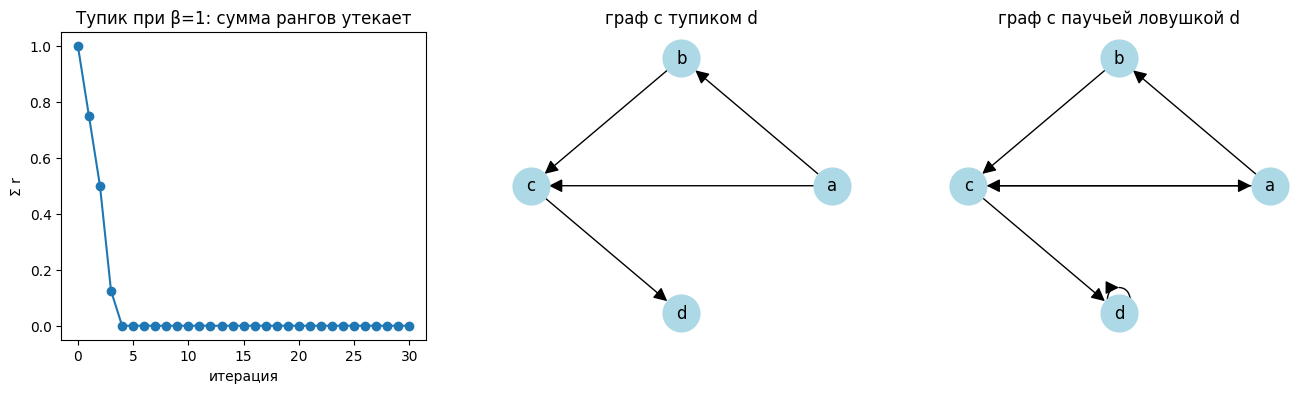

In [6]:
def naive_pagerank(G, n_iter=30, beta=1.0):
    """Базовый принцип без обработки тупиков; beta < 1 добавляет телепортацию."""
    nodes = list(G.nodes()); N = len(nodes)
    r = {v: 1 / N for v in nodes}
    history = [sum(r.values())]
    for _ in range(n_iter):
        r = {j: beta * sum(r[i] / G.out_degree(i) for i in G.predecessors(j)) + (1 - beta) / N for j in nodes}
        history.append(sum(r.values()))
    return r, history

dead_end = nx.DiGraph([("a", "b"), ("a", "c"), ("b", "c"), ("c", "d")])      # d - тупик
trap = nx.DiGraph([("a", "b"), ("a", "c"), ("b", "c"), ("c", "d"), ("d", "d"), ("c", "a")])  # d - ловушка

r_de, h_de = naive_pagerank(dead_end)
r_tr, h_tr = naive_pagerank(trap)
print("Тупик, β=1:      ", {k: round(v, 4) for k, v in r_de.items()}, " сумма рангов =", round(h_de[-1], 6))
print("Тупик, PageRank: ", {k: round(v, 4) for k, v in nx.pagerank(dead_end).items()})
print("Ловушка, β=1:    ", {k: round(v, 4) for k, v in r_tr.items()})
print("Ловушка, β=0.85: ", {k: round(v, 4) for k, v in naive_pagerank(trap, beta=0.85)[0].items()})

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(h_de, marker="o"); axes[0].set_title("Тупик при β=1: сумма рангов утекает")
axes[0].set_xlabel("итерация"); axes[0].set_ylabel("Σ r")
for ax, g, title in [(axes[1], dead_end, "граф с тупиком d"), (axes[2], trap, "граф с паучьей ловушкой d")]:
    nx.draw_networkx(g, nx.circular_layout(g), ax=ax, node_color="lightblue", node_size=700, arrowsize=20)
    ax.set_title(title); ax.axis("off")
plt.show()

## 4. Влияние β и персонализированный PageRank

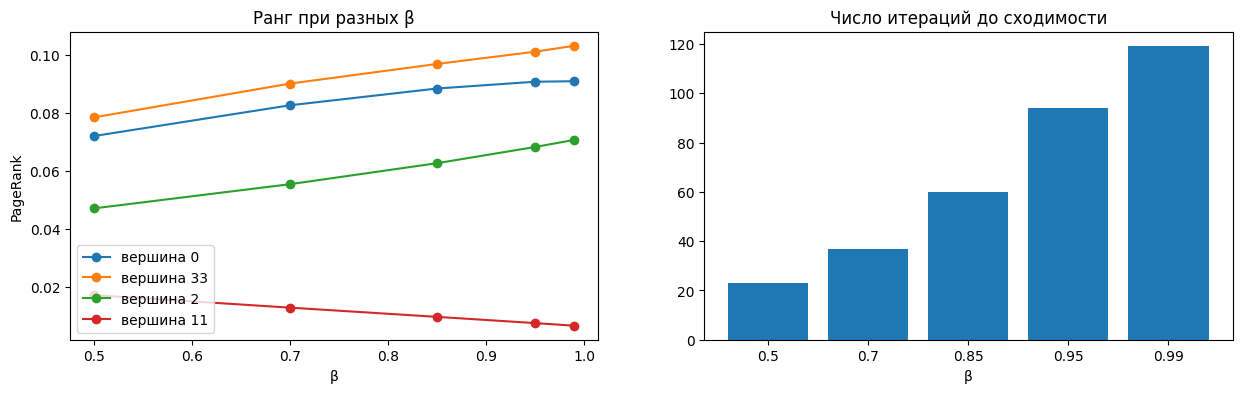

In [7]:
K = nx.karate_club_graph().to_directed()
betas = [0.5, 0.7, 0.85, 0.95, 0.99]
res = pd.DataFrame({b: nx.pagerank(K, alpha=b) for b in betas})
iters = []
for b in betas:
    _, n = pagerank_power(K, beta=b, eps=1e-10)
    iters.append(n)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for node in [0, 33, 2, 11]:
    axes[0].plot(betas, res.loc[node], marker="o", label=f"вершина {node}")
axes[0].set_xlabel("β"); axes[0].set_ylabel("PageRank"); axes[0].legend(); axes[0].set_title("Ранг при разных β")
axes[1].bar([str(b) for b in betas], iters); axes[1].set_title("Число итераций до сходимости")
axes[1].set_xlabel("β")
plt.show()

При $\beta \to 1$ ранги сильнее зависят от структуры ссылок: хабы 0 и 33 растут, а листья (вершина 11) падают.
Сходимость при этом замедляется, потому что скорость сходимости определяется $\beta$ (второе собственное число $\le \beta$).
Значение 0.85 — классический компромисс.

**Персонализированный PageRank:** телепортация идёт не на любую страницу, а только на заданное множество
(например, на «интересы пользователя»). Это даёт меру близости к выбранным узлам.

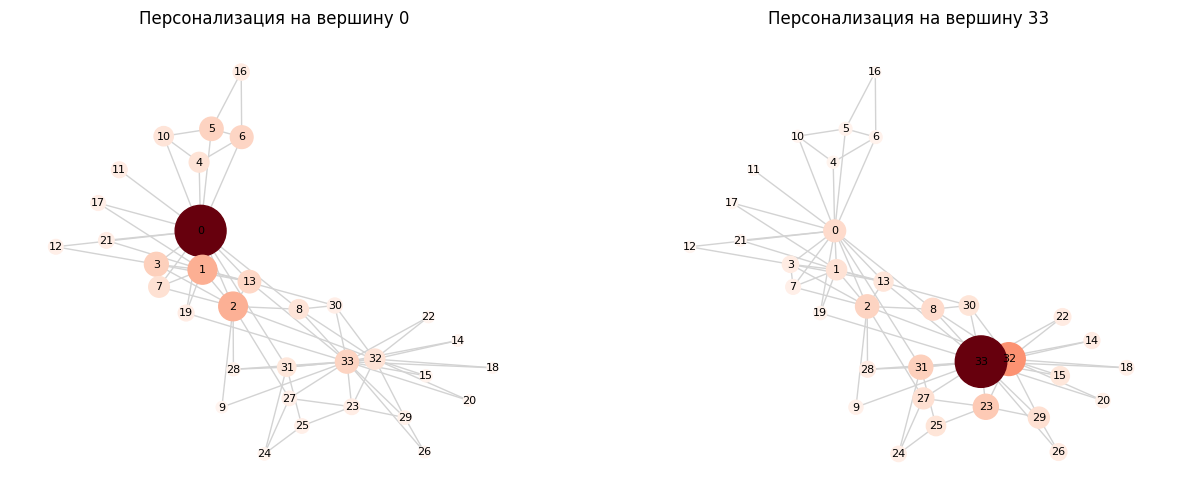

In [8]:
pr_0 = nx.pagerank(K, personalization={0: 1})
pr_33 = nx.pagerank(K, personalization={33: 1})
pos = nx.spring_layout(K, seed=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, pr, t in [(axes[0], pr_0, "Персонализация на вершину 0"), (axes[1], pr_33, "Персонализация на вершину 33")]:
    nx.draw_networkx(K.to_undirected(), pos, ax=ax, node_color=[pr[n] for n in K], cmap="Reds",
                     node_size=[5000 * pr[n] + 50 for n in K], font_size=8, edge_color="lightgray")
    ax.set_title(t); ax.axis("off")
plt.show()

## 5. Пример 2 из задания: ранжирование реальных веб-страниц

В примере из задания есть недочёты: ссылки берутся только с одной страницы (получается граф-«звезда», где у всех
страниц одинаковый ранг), относительные адреса не превращаются в абсолютные, а ссылки без `href` вызывают ошибку.
Исправленная версия:
- **краулер в ширину (BFS)** обходит до `MAX_PAGES` страниц одного раздела сайта;
- ссылки нормализуются через `urljoin`, якоря (`#...`) отбрасываются, остаются только страницы того же раздела;
- граф строится **между обойдёнными страницами**, и PageRank становится содержательным.

Обходим статьи русской Википедии, начиная со статьи «PageRank». Делаем паузу между запросами и указываем User-Agent
(этого требуют правила Википедии). Результат обхода кэшируется в `crawl_cache.json`.

In [9]:
START_URL = "https://ru.wikipedia.org/wiki/PageRank"
MAX_PAGES = 80
HEADERS = {"User-Agent": "GraphML-study-notebook/1.0 (educational PageRank example)"}
CACHE = "crawl_cache.json"

def is_article(url):
    p = urlparse(url)
    return p.netloc == "ru.wikipedia.org" and p.path.startswith("/wiki/") and ":" not in unquote(p.path[6:])

def get_links(url):
    response = requests.get(url, headers=HEADERS, timeout=20)
    soup = BeautifulSoup(response.content, "html.parser")
    body = soup.find("div", id="mw-content-text") or soup
    # навигационные шаблоны, сноски и инфобоксы связывают "всё со всем" - убираем их,
    # оставляя только ссылки из основного текста статьи
    for junk in body.select(".navbox, .navbox-styles, .reflist, .references, .infobox, .metadata, .ambox"):
        junk.decompose()
    links = set()
    for a in body.find_all("a", href=True):              # href может отсутствовать
        dst = urljoin(url, a["href"]).split("#")[0]      # относительные -> абсолютные
        if is_article(dst) and dst != url:
            links.add(dst)
    return links

def crawl(start, max_pages):
    graph, queue, seen = {}, deque([start]), {start}
    while queue and len(graph) < max_pages:
        url = queue.popleft()
        try:
            graph[url] = sorted(get_links(url))
        except requests.RequestException as e:
            print("ошибка", url, e)
            continue
        for dst in graph[url]:
            if dst not in seen:
                seen.add(dst); queue.append(dst)
        time.sleep(0.3)
    return graph

if os.path.exists(CACHE):
    with open(CACHE, encoding="utf-8") as f:
        link_graph = json.load(f)
else:
    link_graph = crawl(START_URL, MAX_PAGES)
    with open(CACHE, "w", encoding="utf-8") as f:
        json.dump(link_graph, f, ensure_ascii=False)
print("Обойдено страниц:", len(link_graph), "| всего найдено ссылок:", sum(map(len, link_graph.values())))

Обойдено страниц: 80 | всего найдено ссылок: 13025


In [10]:
title = lambda u: unquote(urlparse(u).path[6:]).replace("_", " ")

# Граф ссылок между обойдёнными страницами
W = nx.DiGraph()
W.add_nodes_from(link_graph)
for src, dsts in link_graph.items():
    for dst in dsts:
        if dst in link_graph:
            W.add_edge(src, dst)
print(W)

pr_web = nx.pagerank(W)
my_pr = pagerank_iterative(W)
print("max |моя реализация - networkx| = {:.2e}".format(max(abs(pr_web[v] - my_pr[v]) for v in W)))

top = pd.DataFrame({
    "страница": [title(u) for u in W],
    "PageRank": [pr_web[u] for u in W],
    "входящих ссылок": [W.in_degree(u) for u in W],
    "исходящих ссылок": [W.out_degree(u) for u in W],
}).sort_values("PageRank", ascending=False).reset_index(drop=True)
top["ранг по входящим"] = top["входящих ссылок"].rank(ascending=False, method="min").astype(int)
top.head(15).round(4)

DiGraph with 80 nodes and 459 edges
max |моя реализация - networkx| = 1.05e-05


,страница,PageRank,входящих ссылок,исходящих ссылок,ранг по входящим
0,Английский язык,0.1124,38,0,2
1,Google (компания),0.0806,39,58,1
2,2004 год,0.0364,14,11,5
3,2003 год,0.0315,13,8,6
4,Apple,0.0306,13,4,6
5,1996 год,0.0290,11,10,10
6,Android,0.0286,16,6,4
7,2010 год,0.0281,11,10,10
8,1998 год,0.0277,13,8,6
9,2012 год,0.0274,11,9,10


Корреляция Спирмена между PageRank и числом входящих ссылок: 0.973


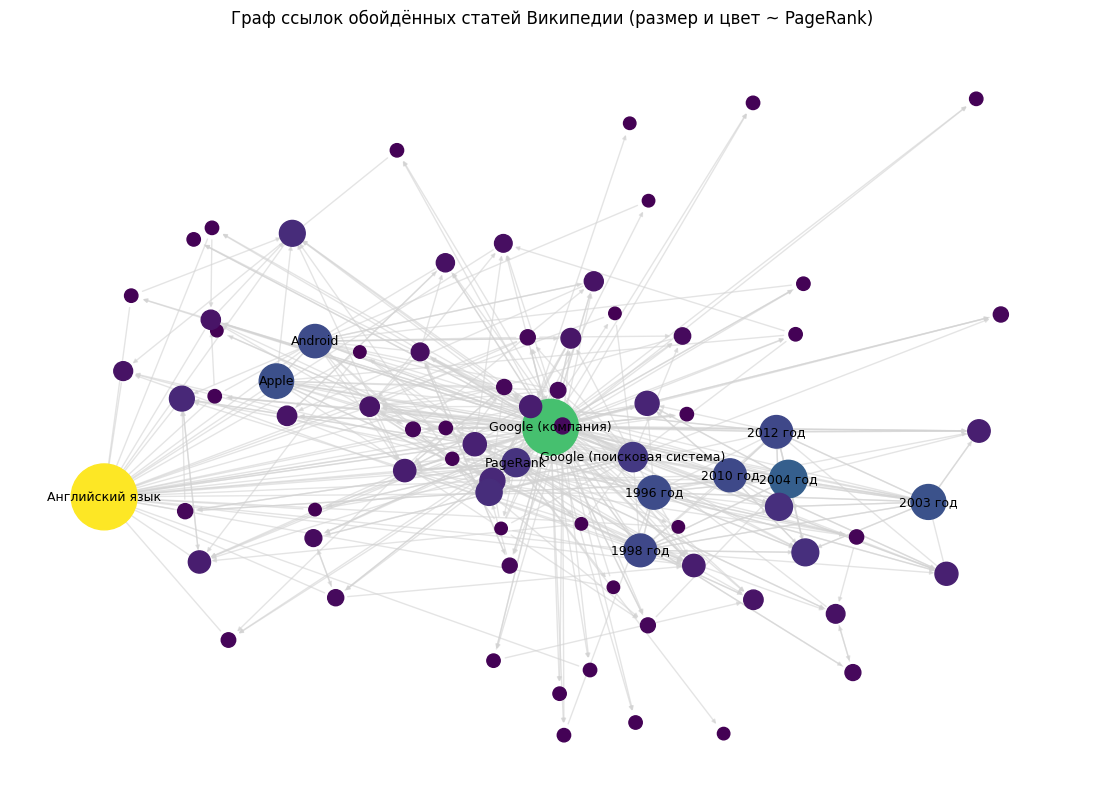

In [11]:
from scipy.stats import spearmanr
rho = spearmanr(top["PageRank"], top["входящих ссылок"]).correlation
print(f"Корреляция Спирмена между PageRank и числом входящих ссылок: {rho:.3f}")

plt.figure(figsize=(14, 10))
pw = nx.spring_layout(W, seed=4, k=0.6)
nx.draw_networkx_edges(W, pw, edge_color="lightgray", arrowsize=6, alpha=0.6)
nx.draw_networkx_nodes(W, pw, node_size=[20000 * pr_web[u] for u in W],
                       node_color=[pr_web[u] for u in W], cmap="viridis")
best = set(top["страница"].head(12))
nx.draw_networkx_labels(W, pw, labels={u: title(u) for u in W if title(u) in best}, font_size=9)
plt.title("Граф ссылок обойдённых статей Википедии (размер и цвет ~ PageRank)")
plt.axis("off")
plt.show()

## Выводы

1. PageRank оценивает важность узла по важности тех, кто на него ссылается. Это задача поиска стационарного
   распределения случайного блуждания, то есть главного собственного вектора матрицы Google.
2. Реализованы три способа вычисления: итеративный по формуле (шаги «инициализация → обновление → повторение до сходимости»),
   матричный power iteration и прямой расчёт собственного вектора. Все совпадают с `nx.pagerank` с точностью до $10^{-6}$ и лучше.
3. Базовый принцип без телепортации ломается на тупиках (ранг утекает) и паучьих ловушках (ранг захватывается).
   Телепортация с вероятностью $1-\beta$ и равномерный переход из тупиков решают обе проблемы и гарантируют единственное решение.
4. Чем больше $\beta$, тем сильнее учитывается структура и тем медленнее сходимость. Персонализированный PageRank даёт ранжирование
   «относительно» выбранных узлов и используется в рекомендательных системах.
5. Исправленный пример 2 строит реальный граф ссылок обходом в ширину. PageRank коррелирует с числом входящих ссылок, но не совпадает с ним:
   ссылка от важной страницы весит больше, чем много ссылок от второстепенных.